In [ ]:
!wget https://archive.ics.uci.edu/ml/machine-learning-databases/00231/PAMAP2_Dataset.zip

--2026-11-16 02:30:23--  https://archive.ics.uci.edu/ml/machine-learning-databases/00231/PAMAP2_Dataset.zip
Resolving archive.ics.uci.edu (archive.ics.uci.edu)... 128.195.10.252
Connecting to archive.ics.uci.edu (archive.ics.uci.edu)|128.195.10.252|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: unspecified
Saving to: ‘PAMAP2_Dataset.zip’

PAMAP2_Dataset.zip      [                <=> ] 656.29M  74.2MB/s    in 11s     

2026-11-16 02:30:34 (59.6 MB/s) - ‘PAMAP2_Dataset.zip’ saved [688167640]



In [ ]:
!unzip -q PAMAP2_Dataset.zip
!ls PAMAP2_Dataset/
!ls PAMAP2_Dataset/Protocol/ | head

DataCollectionProtocol.pdf	Protocol
DescriptionOfActivities.pdf	readme.pdf
Optional			subjectInformation.pdf
PerformedActivitiesSummary.pdf
subject101.dat
subject102.dat
subject103.dat
subject104.dat
subject105.dat
subject106.dat
subject107.dat
subject108.dat
subject109.dat


In [ ]:
!pip install shap captum

In [ ]:
import shap
import captum
import torch
print(shap.__version__)
print(captum.__version__)
print(torch.__version__, torch.cuda.is_available())

0.54.1
0.9.0
2.14.1+cu130 True


In [ ]:
import pandas as pd
import numpy as np

df = pd.read_csv('PAMAP2_Dataset/Protocol/subject101.dat', sep=r'\s+', header=None)
print('shape:', df.shape)
print(df[1].value_counts().sort_index())
print('NaN 总数:', df.isna().sum().sum())

shape: (376417, 54)
1
0     126460
1      27187
2      23480
3      21717
4      22253
5      21265
6      23575
7      20265
12     15890
13     14899
16     22941
17     23573
24     12912
Name: count, dtype: int64
NaN 总数: 397958


In [ ]:
nan_counts = df.isna().sum()
print(nan_counts[nan_counts > 0])
print('去掉活动0后剩余:', (df[1] != 0).sum())

2     342028
3       1454
4       1454
5       1454
6       1454
7       1454
8       1454
9       1454
10      1454
11      1454
12      1454
13      1454
14      1454
15      1454
16      1454
17      1454
18      1454
19      1454
20       509
21       509
22       509
23       509
24       509
25       509
26       509
27       509
28       509
29       509
30       509
31       509
32       509
33       509
34       509
35       509
36       509
37      1327
38      1327
39      1327
40      1327
41      1327
42      1327
43      1327
44      1327
45      1327
46      1327
47      1327
48      1327
49      1327
50      1327
51      1327
52      1327
53      1327
dtype: int64
去掉活动0后剩余: 249957


In [ ]:
# 1. 去掉活动0（过渡段）
df = df[df[1] != 0].copy()

# 2. 去掉心率列（第2列）
df = df.drop(columns=[2])

# 3. 线性插值补 IMU 的短缺口
df = df.interpolate(method='linear', limit_direction='both')

print('shape:', df.shape)
print('NaN 总数:', df.isna().sum().sum())

shape: (249957, 53)
NaN 总数: 0


In [ ]:
# 选通道：每个 IMU 留 acc16 + gyro + mag（各3轴），共 27 列
hand_cols  = [4,5,6,10,11,12,13,14,15]
chest_cols = [21,22,23,27,28,29,30,31,32]
ankle_cols = [38,39,40,44,45,46,47,48,49]
sensor_cols = hand_cols + chest_cols + ankle_cols

WINDOW = 512   # 5.12秒 @100Hz，PAMAP2 文献常用窗口
STEP = 256     # 50% 重叠

df = df.reset_index(drop=True)
# 连续段：活动ID不变 且 时间戳连续（间隔>0.05s就断开，不跨断口切窗）
seg_id = (df[1].ne(df[1].shift()) | (df[0].diff().abs() > 0.05)).cumsum()

X_list, y_list = [], []
for _, seg in df.groupby(seg_id):
    label = seg[1].iloc[0]
    data = seg[sensor_cols].values
    for start in range(0, len(data) - WINDOW + 1, STEP):
        X_list.append(data[start:start+WINDOW])
        y_list.append(label)

X = np.array(X_list)
y = np.array(y_list)
print('X:', X.shape)
print('y:', y.shape)
print(pd.Series(y).value_counts().sort_index())

X: (956, 512, 27)
y: (956,)
1     105
2      90
3      83
4      85
5      82
6      91
7      78
12     59
13     55
16     88
17     91
24     49
Name: count, dtype: int64


In [ ]:
def load_subject(path):
    df = pd.read_csv(path, sep=r'\s+', header=None)
    df = df[df[1] != 0].copy()
    df = df.drop(columns=[2])
    df = df.interpolate(method='linear', limit_direction='both')
    df = df.reset_index(drop=True)
    seg_id = (df[1].ne(df[1].shift()) | (df[0].diff().abs() > 0.05)).cumsum()
    X_list, y_list = [], []
    for _, seg in df.groupby(seg_id):
        label = seg[1].iloc[0]
        data = seg[sensor_cols].values
        for start in range(0, len(data) - WINDOW + 1, STEP):
            X_list.append(data[start:start+WINDOW])
            y_list.append(label)
    return np.array(X_list, dtype=np.float32), np.array(y_list)

X_all, y_all, s_all = [], [], []
for i in range(101, 110):
    Xi, yi = load_subject(f'PAMAP2_Dataset/Protocol/subject{i}.dat')
    X_all.append(Xi); y_all.append(yi)
    s_all.append(np.full(len(yi), i))
    print(f'subject{i}: {len(yi)} windows')

X_all = np.concatenate(X_all)
y_all = np.concatenate(y_all)
s_all = np.concatenate(s_all)
print('total:', X_all.shape, y_all.shape, s_all.shape)

np.savez('pamap2_windows.npz', X=X_all, y=y_all, s=s_all)


subject101: 956 windows
subject102: 1008 windows
subject103: 667 windows
subject104: 886 windows
subject105: 1044 windows
subject106: 959 windows
subject107: 890 windows
subject108: 1002 windows
subject109: 23 windows
total: (7435, 512, 27) (7435,) (7435,)


In [ ]:
# 去掉 subject109
mask = s_all != 109
X_all, y_all, s_all = X_all[mask], y_all[mask], s_all[mask]

# 标签映射成 0–11（CNN 需要连续编号）
act_ids = [1,2,3,4,5,6,7,12,13,16,17,24]
id2idx = {a: i for i, a in enumerate(act_ids)}
y_idx = np.array([id2idx[v] for v in y_all])

# 按人划分：101–106 训练，107–108 测试
train_mask = np.isin(s_all, [101,102,103,104,105,106])
test_mask = np.isin(s_all, [107,108])
X_train, y_train = X_all[train_mask], y_idx[train_mask]
X_test, y_test = X_all[test_mask], y_idx[test_mask]
print('train:', X_train.shape, 'test:', X_test.shape)
print('train分布:', pd.Series(y_train).value_counts().sort_index().to_dict())
print('test分布:', pd.Series(y_test).value_counts().sort_index().to_dict())

np.savez('pamap2_windows.npz', X=X_all, y=y_all, s=s_all)


train: (5520, 512, 27) test: (1892, 512, 27)
train分布: {0: 550, 1: 577, 2: 534, 3: 669, 4: 300, 5: 449, 6: 503, 7: 325, 8: 308, 9: 497, 10: 680, 11: 128}
test分布: {0: 192, 1: 134, 2: 196, 3: 252, 4: 76, 5: 185, 6: 222, 7: 109, 8: 76, 9: 176, 10: 241, 11: 33}


In [ ]:
def extract_features(X):
    mean = X.mean(axis=1)
    std = X.std(axis=1)
    minv = X.min(axis=1)
    maxv = X.max(axis=1)
    return np.concatenate([mean, std, minv, maxv], axis=1)

X_train_feat = extract_features(X_train)
X_test_feat = extract_features(X_test)
print('train feat:', X_train_feat.shape)
print('test feat:', X_test_feat.shape)

# 特征名（之后画 SHAP 图要用到）
axes = ['acc16_x','acc16_y','acc16_z','gyro_x','gyro_y','gyro_z','mag_x','mag_y','mag_z']
ch_names = [f'{loc}_{a}' for loc in ['hand','chest','ankle'] for a in axes]
feat_names = [f'{s}_{c}' for s in ['mean','std','min','max'] for c in ch_names]


train feat: (5520, 108)
test feat: (1892, 108)


In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score, accuracy_score

f1s, accs = [], []
for seed in [0, 1, 2]:
    m = RandomForestClassifier(n_estimators=200, random_state=seed, n_jobs=-1)
    m.fit(X_train_feat, y_train)
    pred = m.predict(X_test_feat)
    f1s.append(f1_score(y_test, pred, average='macro'))
    accs.append(accuracy_score(y_test, pred))
    print(f'seed {seed}: Acc={accs[-1]:.4f} Macro-F1={f1s[-1]:.4f}')
print(f'平均: Acc={np.mean(accs):.4f}±{np.std(accs):.4f} Macro-F1={np.mean(f1s):.4f}±{np.std(f1s):.4f}')

# 留一个 seed=0 的模型，之后算 SHAP 用
rf = RandomForestClassifier(n_estimators=200, random_state=0, n_jobs=-1)
rf.fit(X_train_feat, y_train)

seed 0: Acc=0.8927 Macro-F1=0.8895
seed 1: Acc=0.8959 Macro-F1=0.8932
seed 2: Acc=0.8901 Macro-F1=0.8935
平均: Acc=0.8929±0.0024 Macro-F1=0.8921±0.0018


RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=0)

各位置总体重要度 hand/chest/ankle:
[0.70707235 0.90156409 1.32056175]
[[0.1  0.29 0.25 0.29 0.2  0.2  0.41 0.2  0.22 0.23 0.2  0.21]
 [0.45 0.38 0.38 0.19 0.31 0.3  0.18 0.25 0.33 0.34 0.3  0.36]
 [0.45 0.33 0.37 0.52 0.49 0.5  0.41 0.54 0.45 0.43 0.49 0.43]]


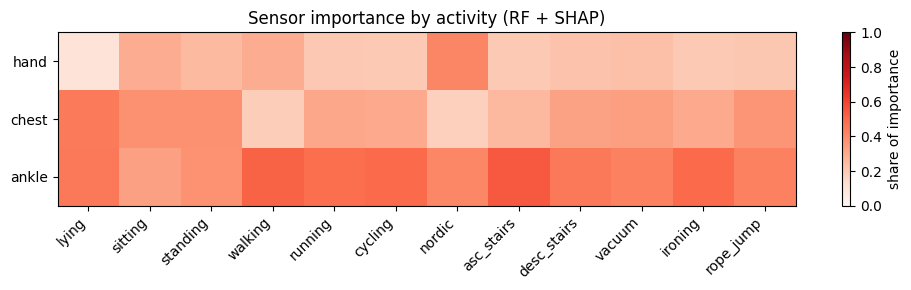

In [ ]:
import matplotlib.pyplot as plt

# TreeSHAP 算测试集上每个特征的 SHAP 值
explainer = shap.TreeExplainer(rf)
sv = explainer(X_test_feat)
shap_vals = np.abs(sv.values).mean(axis=0)  # (108, 12)：每特征、每类的平均 |SHAP|

# 按传感器位置汇总：特征顺序是 [mean, std, min, max] × [hand(9), chest(9), ankle(9)]
loc_importance = np.zeros((3, 12))
for s in range(4):
    block = shap_vals[s*27:(s+1)*27, :]
    loc_importance[0] += block[0:9].sum(axis=0)
    loc_importance[1] += block[9:18].sum(axis=0)
    loc_importance[2] += block[18:27].sum(axis=0)

print('各位置总体重要度 hand/chest/ankle:')
print(loc_importance.sum(axis=1))

# 每类活动内归一化，看"这个活动主要靠哪个传感器"
loc_norm = loc_importance / loc_importance.sum(axis=0, keepdims=True)
print(np.round(loc_norm, 2))

act_names = ['lying','sitting','standing','walking','running','cycling','nordic','asc_stairs','desc_stairs','vacuum','ironing','rope_jump']
plt.figure(figsize=(10, 3))
plt.imshow(loc_norm, aspect='auto', cmap='Reds', vmin=0, vmax=1)
plt.xticks(range(12), act_names, rotation=45, ha='right')
plt.yticks(range(3), ['hand','chest','ankle'])
plt.colorbar(label='share of importance')
plt.title('Sensor importance by activity (RF + SHAP)')
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.metrics import f1_score

def eval_with_deleted(feat_idx):
    Xd = X_test_feat.copy()
    Xd[:, feat_idx] = 0
    pred = rf.predict(Xd)
    return f1_score(y_test, pred, average='macro')

base_f1 = f1_score(y_test, rf.predict(X_test_feat), average='macro')
print('baseline Macro-F1:', base_f1)

# 每个位置的特征下标：每统计量块内 hand 0-8, chest 9-17, ankle 18-26
loc_idx = {}
for loc, (a, b) in {'hand': (0,9), 'chest': (9,18), 'ankle': (18,27)}.items():
    idx = []
    for s in range(4):
        idx.extend(range(s*27+a, s*27+b))
    loc_idx[loc] = idx

for loc in ['hand', 'chest', 'ankle']:
    f1 = eval_with_deleted(loc_idx[loc])
    print(f'删 {loc}: Macro-F1={f1:.4f} (下降 {base_f1-f1:.4f})')

# 随机删 36 个特征，重复 5 次取平均
rng = np.random.RandomState(0)
rand_drops = []
for _ in range(5):
    idx = rng.choice(108, size=36, replace=False)
    rand_drops.append(base_f1 - eval_with_deleted(idx))
print(f'随机删36特征: 平均下降 {np.mean(rand_drops):.4f}±{np.std(rand_drops):.4f}')

baseline Macro-F1: 0.8895374837548277
删 hand: Macro-F1=0.6272 (下降 0.2623)
删 chest: Macro-F1=0.5241 (下降 0.3655)
删 ankle: Macro-F1=0.2321 (下降 0.6574)
随机删36特征: 平均下降 0.2141±0.0650


In [ ]:
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

device = 'cuda' if torch.cuda.is_available() else 'cpu'

# 标准化：只用训练集的均值/标准差
mean = X_train.mean(axis=(0, 1))
std = X_train.std(axis=(0, 1))
std[std == 0] = 1
X_train_n = (X_train - mean) / std
X_test_n = (X_test - mean) / std

class CNN1D(nn.Module):
    def __init__(self, n_channels=27, n_classes=12):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv1d(n_channels, 64, 5, padding=2), nn.BatchNorm1d(64), nn.ReLU(), nn.MaxPool1d(2),
            nn.Conv1d(64, 128, 5, padding=2), nn.BatchNorm1d(128), nn.ReLU(), nn.MaxPool1d(2),
            nn.Conv1d(128, 128, 5, padding=2), nn.BatchNorm1d(128), nn.ReLU(), nn.MaxPool1d(2),
        )
        self.classifier = nn.Linear(128, n_classes)

    def forward(self, x):
        x = self.features(x)   # (B, 128, 64)
        x = x.mean(dim=2)      # 全局平均池化 -> (B, 128)
        return self.classifier(x)

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score, accuracy_score

def train_one(seed):
    torch.manual_seed(seed); np.random.seed(seed)
    idx_tr, idx_val = train_test_split(np.arange(len(y_train)), test_size=0.1,
                                       random_state=seed, stratify=y_train)
    Xtr = torch.tensor(X_train_n[idx_tr].transpose(0,2,1), dtype=torch.float32)
    ytr = torch.tensor(y_train[idx_tr], dtype=torch.long)
    Xva = torch.tensor(X_train_n[idx_val].transpose(0,2,1), dtype=torch.float32)
    yva = torch.tensor(y_train[idx_val], dtype=torch.long)
    Xte = torch.tensor(X_test_n.transpose(0,2,1), dtype=torch.float32)
    train_dl = DataLoader(TensorDataset(Xtr, ytr), batch_size=64, shuffle=True)
    val_dl = DataLoader(TensorDataset(Xva, yva), batch_size=256)
    test_dl = DataLoader(TensorDataset(Xte, torch.tensor(y_test, dtype=torch.long)), batch_size=256)

    model = CNN1D().to(device)
    opt = torch.optim.Adam(model.parameters(), lr=1e-3)
    crit = nn.CrossEntropyLoss()
    best_f1, best_state, bad = -1, None, 0
    for epoch in range(50):
        model.train()
        for xb, yb in train_dl:
            xb, yb = xb.to(device), yb.to(device)
            opt.zero_grad(); loss = crit(model(xb), yb); loss.backward(); opt.step()
        model.eval()
        with torch.no_grad():
            pv = torch.cat([model(xb.to(device)).argmax(1) for xb, _ in val_dl]).cpu().numpy()
        val_f1 = f1_score(yva.numpy(), pv, average='macro')
        if val_f1 > best_f1:
            best_f1, best_state, bad = val_f1, {k: v.cpu().clone() for k, v in model.state_dict().items()}, 0
        else:
            bad += 1
            if bad >= 8:
                break
    model.load_state_dict(best_state)
    model.eval()
    with torch.no_grad():
        pt = torch.cat([model(xb.to(device)).argmax(1) for xb, _ in test_dl]).cpu().numpy()
    test_f1 = f1_score(y_test, pt, average='macro')
    test_acc = accuracy_score(y_test, pt)
    print(f'seed {seed}: epoch={epoch+1} Val-F1={best_f1:.4f} Test Acc={test_acc:.4f} Macro-F1={test_f1:.4f}')
    return model, test_f1, test_acc

models, f1s, accs = [], [], []
for seed in [0, 1, 2]:
    m, f1, acc = train_one(seed)
    models.append(m); f1s.append(f1); accs.append(acc)
print(f'平均: Acc={np.mean(accs):.4f}±{np.std(accs):.4f} Macro-F1={np.mean(f1s):.4f}±{np.std(f1s):.4f}')
cnn = models[0]  # seed=0 的模型，之后算 IG 用

seed 0: epoch=24 Val-F1=0.9958 Test Acc=0.7674 Macro-F1=0.6730
seed 1: epoch=26 Val-F1=0.9886 Test Acc=0.6480 Macro-F1=0.5864
seed 2: epoch=29 Val-F1=0.9872 Test Acc=0.6342 Macro-F1=0.5764
平均: Acc=0.6832±0.0598 Macro-F1=0.6120±0.0433


In [ ]:
s_train = s_all[np.isin(s_all, [101,102,103,104,105,106])]

class CNN1D_v2(nn.Module):
    def __init__(self, n_channels=27, n_classes=12):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv1d(n_channels, 64, 5, padding=2), nn.BatchNorm1d(64), nn.ReLU(), nn.MaxPool1d(2),
            nn.Conv1d(64, 128, 5, padding=2), nn.BatchNorm1d(128), nn.ReLU(), nn.MaxPool1d(2),
            nn.Conv1d(128, 128, 5, padding=2), nn.BatchNorm1d(128), nn.ReLU(), nn.MaxPool1d(2),
        )
        self.dropout = nn.Dropout(0.5)
        self.classifier = nn.Linear(128, n_classes)

    def forward(self, x):
        x = self.features(x)
        x = x.mean(dim=2)
        x = self.dropout(x)
        return self.classifier(x)

def train_one_v2(seed):
    torch.manual_seed(seed); np.random.seed(seed)
    # 101–105 训练，106 做验证（早停看"没见过的人"）
    idx_tr = np.where(np.isin(s_train, [101,102,103,104,105]))[0]
    idx_val = np.where(s_train == 106)[0]
    Xtr = torch.tensor(X_train_n[idx_tr].transpose(0,2,1), dtype=torch.float32)
    ytr = torch.tensor(y_train[idx_tr], dtype=torch.long)
    Xva = torch.tensor(X_train_n[idx_val].transpose(0,2,1), dtype=torch.float32)
    yva = torch.tensor(y_train[idx_val], dtype=torch.long)
    Xte = torch.tensor(X_test_n.transpose(0,2,1), dtype=torch.float32)
    train_dl = DataLoader(TensorDataset(Xtr, ytr), batch_size=64, shuffle=True)
    val_dl = DataLoader(TensorDataset(Xva, yva), batch_size=256)
    test_dl = DataLoader(TensorDataset(Xte, torch.tensor(y_test, dtype=torch.long)), batch_size=256)

    model = CNN1D_v2().to(device)
    opt = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-4)
    crit = nn.CrossEntropyLoss()
    best_f1, best_state, bad = -1, None, 0
    for epoch in range(50):
        model.train()
        for xb, yb in train_dl:
            xb, yb = xb.to(device), yb.to(device)
            opt.zero_grad(); loss = crit(model(xb), yb); loss.backward(); opt.step()
        model.eval()
        with torch.no_grad():
            pv = torch.cat([model(xb.to(device)).argmax(1) for xb, _ in val_dl]).cpu().numpy()
        val_f1 = f1_score(yva.numpy(), pv, average='macro')
        if val_f1 > best_f1:
            best_f1, best_state, bad = val_f1, {k: v.cpu().clone() for k, v in model.state_dict().items()}, 0
        else:
            bad += 1
            if bad >= 8:
                break
    model.load_state_dict(best_state)
    model.eval()
    with torch.no_grad():
        pt = torch.cat([model(xb.to(device)).argmax(1) for xb, _ in test_dl]).cpu().numpy()
    test_f1 = f1_score(y_test, pt, average='macro')
    test_acc = accuracy_score(y_test, pt)
    print(f'seed {seed}: epoch={epoch+1} Val-F1={best_f1:.4f} Test Acc={test_acc:.4f} Macro-F1={test_f1:.4f}')
    return model, test_f1, test_acc, pt

models2, f1s2, accs2, pt0 = [], [], [], None
for seed in [0, 1, 2]:
    m, f1, acc, pt = train_one_v2(seed)
    models2.append(m); f1s2.append(f1); accs2.append(acc)
    if seed == 0:
        pt0 = pt
print(f'平均: Acc={np.mean(accs2):.4f}±{np.std(accs2):.4f} Macro-F1={np.mean(f1s2):.4f}±{np.std(f1s2):.4f}')
cnn = models2[0]  # seed=0 的模型，之后算 IG 用

from sklearn.metrics import classification_report
act_names = ['lying','sitting','standing','walking','running','cycling','nordic','asc_stairs','desc_stairs','vacuum','ironing','rope_jump']
print(classification_report(y_test, pt0, target_names=act_names, digits=3))

seed 0: epoch=10 Val-F1=0.9251 Test Acc=0.6739 Macro-F1=0.6352
seed 1: epoch=10 Val-F1=0.9252 Test Acc=0.6665 Macro-F1=0.6236
seed 2: epoch=15 Val-F1=0.9274 Test Acc=0.6586 Macro-F1=0.5683
平均: Acc=0.6663±0.0063 Macro-F1=0.6090±0.0292
              precision    recall  f1-score   support

       lying      1.000     0.516     0.680       192
     sitting      0.550     0.948     0.696       134
    standing      0.863     0.934     0.897       196
     walking      0.617     0.972     0.755       252
     running      1.000     0.132     0.233        76
     cycling      0.882     0.486     0.627       185
      nordic      1.000     0.500     0.667       222
  asc_stairs      0.744     0.853     0.795       109
 desc_stairs      0.385     0.526     0.444        76
      vacuum      0.401     0.801     0.534       176
     ironing      0.902     0.498     0.642       241
   rope_jump      1.000     0.485     0.653        33

    accuracy                          0.674      1892
   macro

In [ ]:
import sys, gc, torch
sys.last_traceback = None
gc.collect()
torch.cuda.empty_cache()
print('allocated:', torch.cuda.memory_allocated()/1e9, 'GB')
print('reserved:', torch.cuda.memory_reserved()/1e9, 'GB')

allocated: 0.95086592 GB
reserved: 1.063256064 GB


In [ ]:
import torch
torch.cuda.empty_cache()

# 先存模型和标准化参数
torch.save(cnn.state_dict(), 'cnn_seed0_v2.pt')
np.savez('norm_stats.npz', mean=mean, std=std)

from captum.attr import IntegratedGradients

cnn.eval()
ig = IntegratedGradients(cnn)

Xte_t = torch.tensor(X_test_n.transpose(0,2,1), dtype=torch.float32).to(device)
attrs = []
for i in range(0, len(Xte_t), 32):   # 每次 32 个样本（IG 内部会 ×50 步）
    xb = Xte_t[i:i+32]
    with torch.no_grad():
        pred = cnn(xb).argmax(1)
    attr = ig.attribute(xb, target=pred, n_steps=50)
    attrs.append(attr.cpu().numpy())
    if (i // 32) % 10 == 0:
        print(f'{i+len(xb)}/{len(Xte_t)}')
attrs = np.concatenate(attrs)
print('attrs:', attrs.shape)
np.save('cnn_ig_attrs.npy', attrs)

32/1892
352/1892
672/1892
992/1892
1312/1892
1632/1892
attrs: (1892, 27, 512)


各位置总体重要度 hand/chest/ankle:
[0.12512648 0.11857415 0.14317445]
[[0.24 0.51 0.33 0.33 0.35 0.29 0.32 0.29 0.23 0.33 0.42 0.33]
 [0.42 0.21 0.25 0.24 0.28 0.39 0.25 0.32 0.26 0.45 0.26 0.34]
 [0.34 0.29 0.42 0.43 0.37 0.32 0.42 0.39 0.51 0.22 0.32 0.33]]


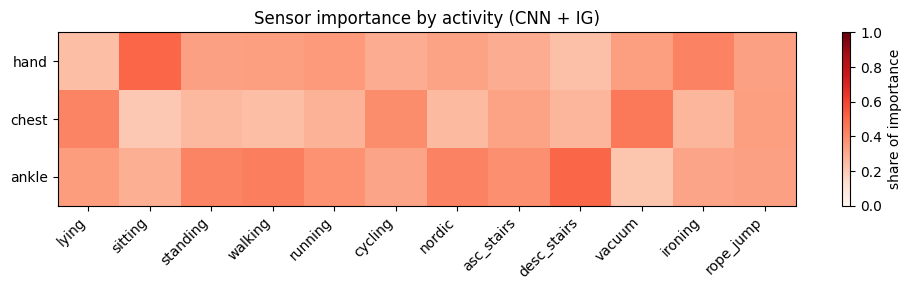

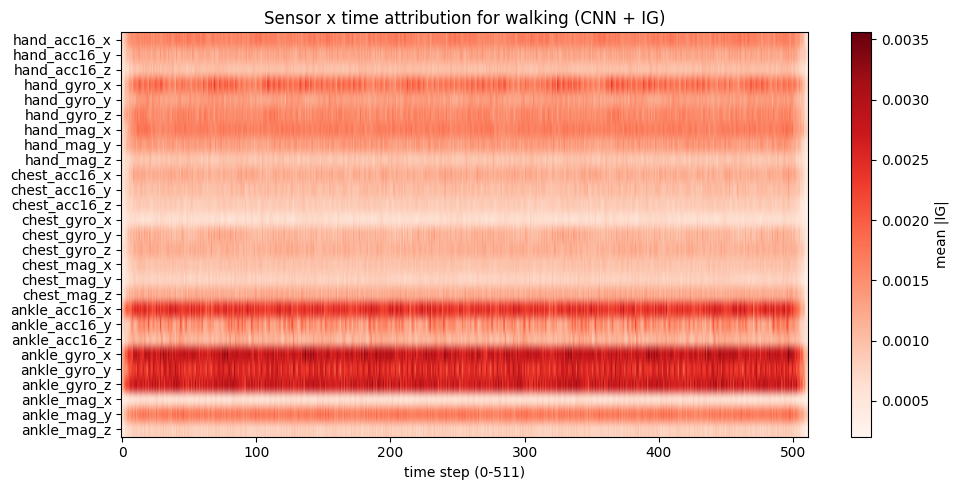

In [ ]:
ch_imp = np.abs(attrs).mean(axis=2)  # (1892, 27)
ig_loc = np.zeros((3, 12))
for c in range(12):
    m = ch_imp[y_test == c].mean(axis=0)
    ig_loc[0, c] = m[0:9].sum()
    ig_loc[1, c] = m[9:18].sum()
    ig_loc[2, c] = m[18:27].sum()

print('各位置总体重要度 hand/chest/ankle:')
print(ig_loc.sum(axis=1))

ig_norm = ig_loc / ig_loc.sum(axis=0, keepdims=True)
print(np.round(ig_norm, 2))

plt.figure(figsize=(10, 3))
plt.imshow(ig_norm, aspect='auto', cmap='Reds', vmin=0, vmax=1)
plt.xticks(range(12), act_names, rotation=45, ha='right')
plt.yticks(range(3), ['hand','chest','ankle'])
plt.colorbar(label='share of importance')
plt.title('Sensor importance by activity (CNN + IG)')
plt.tight_layout()
plt.show()

walk = np.abs(attrs)[y_test == 3].mean(axis=0)  # (27, 512)
plt.figure(figsize=(10, 5))
plt.imshow(walk, aspect='auto', cmap='Reds')
plt.yticks(range(27), ch_names)
plt.xlabel('time step (0-511)')
plt.colorbar(label='mean |IG|')
plt.title('Sensor x time attribution for walking (CNN + IG)')
plt.tight_layout()
plt.show()

In [ ]:
def eval_cnn_deleted(ch_idx):
    Xd = X_test_n.copy()
    Xd[:, :, ch_idx] = 0
    Xt = torch.tensor(Xd.transpose(0,2,1), dtype=torch.float32)
    cnn.eval()
    preds = []
    with torch.no_grad():
        for i in range(0, len(Xt), 256):
            preds.append(cnn(Xt[i:i+256].to(device)).argmax(1).cpu().numpy())
    preds = np.concatenate(preds)
    return f1_score(y_test, preds, average='macro')

base_f1_cnn = eval_cnn_deleted([])
print('baseline Macro-F1:', base_f1_cnn)

for loc, (a, b) in {'hand': (0,9), 'chest': (9,18), 'ankle': (18,27)}.items():
    f1 = eval_cnn_deleted(list(range(a, b)))
    print(f'删 {loc}: Macro-F1={f1:.4f} (下降 {base_f1_cnn-f1:.4f})')

rng = np.random.RandomState(0)
rand_drops = []
for _ in range(5):
    idx = rng.choice(27, size=9, replace=False)
    rand_drops.append(base_f1_cnn - eval_cnn_deleted(idx))
print(f'随机删9通道: 平均下降 {np.mean(rand_drops):.4f}±{np.std(rand_drops):.4f}')

baseline Macro-F1: 0.6352459515980028
删 hand: Macro-F1=0.4629 (下降 0.1724)
删 chest: Macro-F1=0.4201 (下降 0.2152)
删 ankle: Macro-F1=0.4704 (下降 0.1648)
随机删9通道: 平均下降 0.1277±0.0739


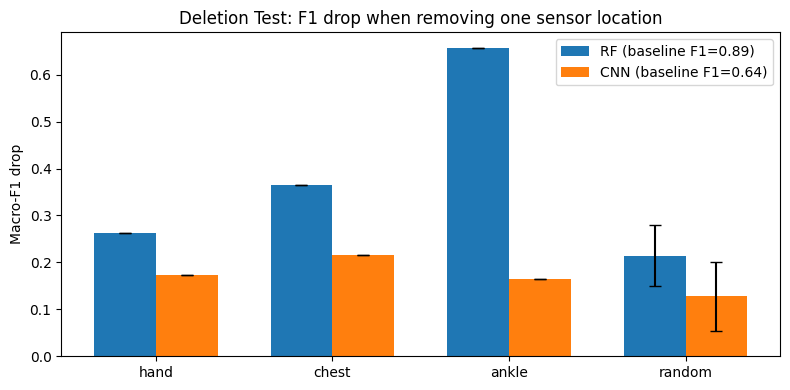

In [ ]:
labels = ['hand', 'chest', 'ankle', 'random']
rf_drops = [0.2623, 0.3655, 0.6574, 0.2141]
cnn_drops = [0.1724, 0.2152, 0.1648, 0.1277]
rf_err = [0, 0, 0, 0.0650]
cnn_err = [0, 0, 0, 0.0739]

x = np.arange(4)
w = 0.35
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(x - w/2, rf_drops, w, yerr=rf_err, capsize=4, label='RF (baseline F1=0.89)')
ax.bar(x + w/2, cnn_drops, w, yerr=cnn_err, capsize=4, label='CNN (baseline F1=0.64)')
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_ylabel('Macro-F1 drop')
ax.set_title('Deletion Test: F1 drop when removing one sensor location')
ax.legend()
plt.tight_layout()
plt.savefig('deletion_test.png', dpi=200)
plt.show()

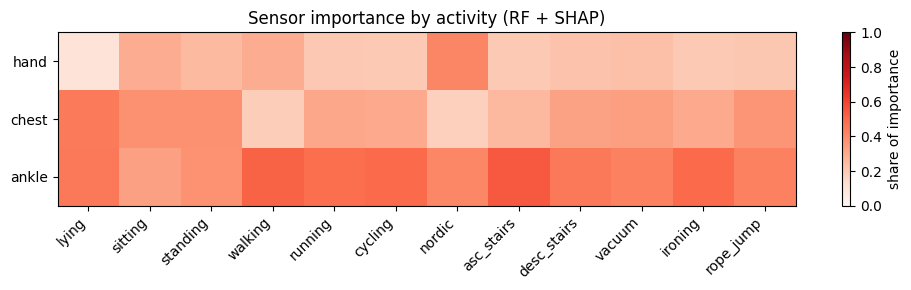

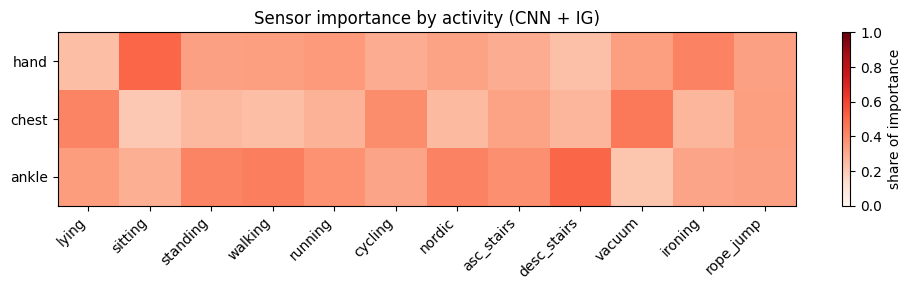

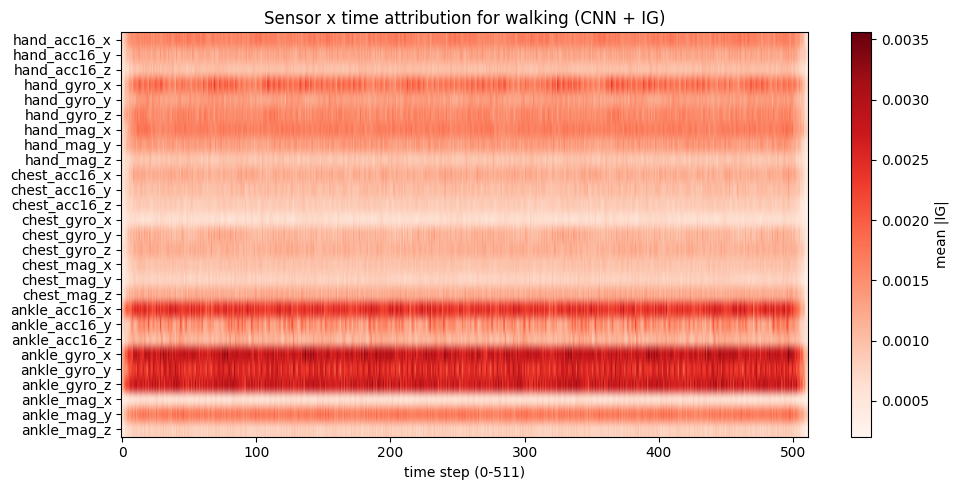

In [ ]:
plt.figure(figsize=(10, 3))
plt.imshow(loc_norm, aspect='auto', cmap='Reds', vmin=0, vmax=1)
plt.xticks(range(12), act_names, rotation=45, ha='right')
plt.yticks(range(3), ['hand','chest','ankle'])
plt.colorbar(label='share of importance')
plt.title('Sensor importance by activity (RF + SHAP)')
plt.tight_layout()
plt.savefig('shap_heatmap.png', dpi=200)
plt.show()

plt.figure(figsize=(10, 3))
plt.imshow(ig_norm, aspect='auto', cmap='Reds', vmin=0, vmax=1)
plt.xticks(range(12), act_names, rotation=45, ha='right')
plt.yticks(range(3), ['hand','chest','ankle'])
plt.colorbar(label='share of importance')
plt.title('Sensor importance by activity (CNN + IG)')
plt.tight_layout()
plt.savefig('ig_heatmap.png', dpi=200)
plt.show()

walk = np.abs(attrs)[y_test == 3].mean(axis=0)
plt.figure(figsize=(10, 5))
plt.imshow(walk, aspect='auto', cmap='Reds')
plt.yticks(range(27), ch_names)
plt.xlabel('time step (0-511)')
plt.colorbar(label='mean |IG|')
plt.title('Sensor x time attribution for walking (CNN + IG)')
plt.tight_layout()
plt.savefig('ig_walking_time.png', dpi=200)
plt.show()

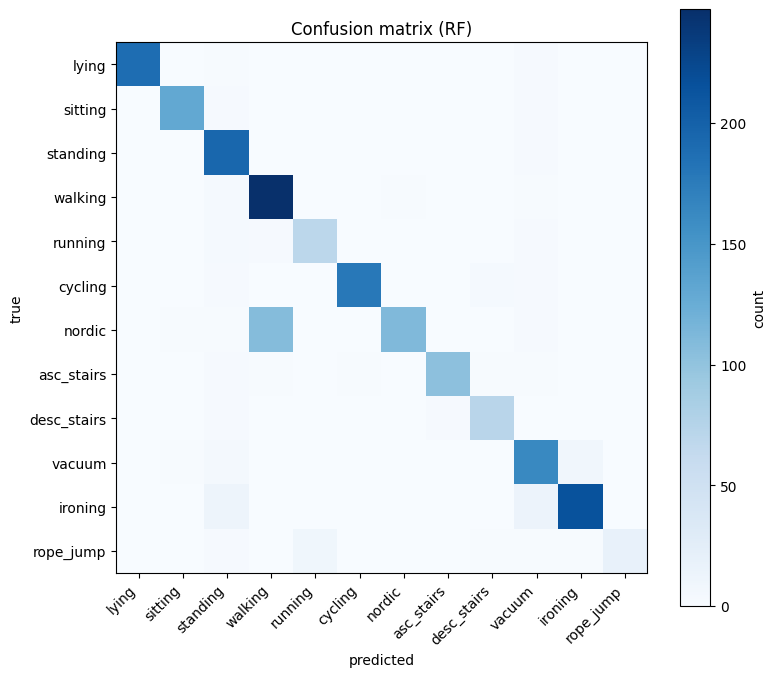

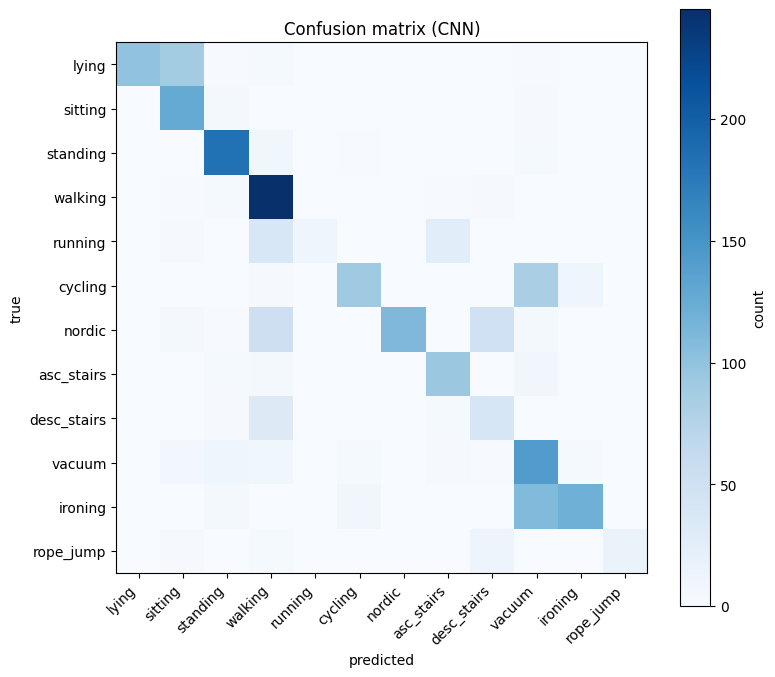

In [ ]:
from sklearn.metrics import confusion_matrix

rf_pred = rf.predict(X_test_feat)
cm_rf = confusion_matrix(y_test, rf_pred)
plt.figure(figsize=(8, 7))
plt.imshow(cm_rf, cmap='Blues')
plt.xticks(range(12), act_names, rotation=45, ha='right')
plt.yticks(range(12), act_names)
plt.xlabel('predicted')
plt.ylabel('true')
plt.colorbar(label='count')
plt.title('Confusion matrix (RF)')
plt.tight_layout()
plt.savefig('cm_rf.png', dpi=200)
plt.show()

cm_cnn = confusion_matrix(y_test, pt0)
plt.figure(figsize=(8, 7))
plt.imshow(cm_cnn, cmap='Blues')
plt.xticks(range(12), act_names, rotation=45, ha='right')
plt.yticks(range(12), act_names)
plt.xlabel('predicted')
plt.ylabel('true')
plt.colorbar(label='count')
plt.title('Confusion matrix (CNN)')
plt.tight_layout()
plt.savefig('cm_cnn.png', dpi=200)
plt.show()


In [ ]:
def per_class_f1_deleted(feat_idx, target_class):
    Xd = X_test_feat.copy()
    Xd[:, feat_idx] = 0
    pred = rf.predict(Xd)
    return f1_score(y_test, pred, average=None, labels=[target_class])[0]

for name, c in [('ironing', 10), ('nordic', 6), ('walking', 3)]:
    base = per_class_f1_deleted([], c)
    print(f'{name} baseline F1={base:.4f}')
    for loc in ['hand', 'chest', 'ankle']:
        f1 = per_class_f1_deleted(loc_idx[loc], c)
        print(f'  删 {loc}: F1={f1:.4f} (下降 {base-f1:.4f})')


ironing baseline F1=0.9247
  删 hand: F1=0.5602 (下降 0.3645)
  删 chest: F1=0.1000 (下降 0.8247)
  删 ankle: F1=0.0165 (下降 0.9083)
nordic baseline F1=0.6607
  删 hand: F1=0.0000 (下降 0.6607)
  删 chest: F1=0.6490 (下降 0.0117)
  删 ankle: F1=0.0000 (下降 0.6607)
walking baseline F1=0.8098
  删 hand: F1=0.7297 (下降 0.0801)
  删 chest: F1=0.7376 (下降 0.0722)
  删 ankle: F1=0.0000 (下降 0.8098)


In [ ]:
!zip -r t7_results.zip *.png *.npz *.npy *.pt

  adding: cm_cnn.png (deflated 19%)
  adding: cm_rf.png (deflated 19%)
  adding: deletion_test.png (deflated 20%)
  adding: ig_heatmap.png (deflated 14%)
  adding: ig_walking_time.png (deflated 2%)
  adding: shap_heatmap.png (deflated 14%)
  adding: norm_stats.npz (deflated 44%)
  adding: pamap2_windows.npz (deflated 53%)
  adding: cnn_ig_attrs.npy (deflated 6%)
  adding: cnn_seed0_v2.pt (deflated 8%)


In [ ]:
!zip -r t7_small.zip *.png *.npy *.pt norm_stats.npz

  adding: cm_cnn.png (deflated 19%)
  adding: cm_rf.png (deflated 19%)
  adding: deletion_test.png (deflated 20%)
  adding: ig_heatmap.png (deflated 14%)
  adding: ig_walking_time.png (deflated 2%)
  adding: shap_heatmap.png (deflated 14%)
  adding: cnn_ig_attrs.npy (deflated 6%)
  adding: cnn_seed0_v2.pt (deflated 8%)
  adding: norm_stats.npz (deflated 44%)


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
!mkdir -p "/content/drive/MyDrive/T7"
!cp t7_small.zip pamap2_windows.npz "/content/drive/MyDrive/T7/"

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
!cp "/content/drive/MyDrive/T7/pamap2_windows.npz" /content/

In [ ]:
import numpy as np, pandas as pd
from sklearn.ensemble import RandomForestClassifier

d = np.load('pamap2_windows.npz')
X_all, y_all, s_all = d['X'], d['y'], d['s']

act_ids = [1,2,3,4,5,6,7,12,13,16,17,24]
id2idx = {a: i for i, a in enumerate(act_ids)}
y_idx = np.array([id2idx[v] for v in y_all])
train_mask = np.isin(s_all, [101,102,103,104,105,106])
test_mask = np.isin(s_all, [107,108])
X_train, y_train = X_all[train_mask], y_idx[train_mask]
X_test, y_test = X_all[test_mask], y_idx[test_mask]

def extract_features(X):
    mean = X.mean(axis=1)
    std = X.std(axis=1)
    minv = X.min(axis=1)
    maxv = X.max(axis=1)
    return np.concatenate([mean, std, minv, maxv], axis=1)

X_train_feat = extract_features(X_train)
X_test_feat = extract_features(X_test)

rf = RandomForestClassifier(n_estimators=200, random_state=0, n_jobs=-1)
rf.fit(X_train_feat, y_train)

loc_idx = {}
for loc, (a, b) in {'hand': (0,9), 'chest': (9,18), 'ankle': (18,27)}.items():
    idx = []
    for s in range(4):
        idx.extend(range(s*27+a, s*27+b))
    loc_idx[loc] = idx

act_names = ['lying','sitting','standing','walking','running','cycling','nordic','asc_stairs','desc_stairs','vacuum','ironing','rope_jump']
print('重载完成:', X_train_feat.shape, X_test_feat.shape)

重载完成: (5520, 108) (1892, 108)


In [ ]:
Xd = X_test_feat.copy()
Xd[:, loc_idx['ankle']] = 0
pred_noankle = rf.predict(Xd)
iron_mask = y_test == 10
print('删脚踝后，熨衣服样本的预测分布:')
print(pd.Series(pred_noankle[iron_mask]).map(lambda i: act_names[i]).value_counts())

pred_base = rf.predict(X_test_feat)
print('不删，熨衣服样本的预测分布:')
print(pd.Series(pred_base[iron_mask]).map(lambda i: act_names[i]).value_counts())

删脚踝后，熨衣服样本的预测分布:
sitting     151
standing     64
lying        20
vacuum        4
ironing       2
Name: count, dtype: int64
不删，熨衣服样本的预测分布:
ironing     215
vacuum       14
standing     12
Name: count, dtype: int64


In [ ]:
from sklearn.metrics import f1_score

# 用训练集均值填充代替置 0（输入保持在分布内）
train_mean = X_train_feat.mean(axis=0)

Xd = X_test_feat.copy()
Xd[:, loc_idx['ankle']] = train_mean[loc_idx['ankle']]
pred_mean = rf.predict(Xd)
iron_mask = y_test == 10
print('均值填充删脚踝后，熨衣服样本的预测分布:')
print(pd.Series(pred_mean[iron_mask]).map(lambda i: act_names[i]).value_counts())
print('ironing F1:', f1_score(y_test, pred_mean, average=None, labels=[10])[0])

均值填充删脚踝后，熨衣服样本的预测分布:
vacuum      159
cycling      69
sitting       8
standing      5
Name: count, dtype: int64
ironing F1: 0.0


In [ ]:
def eval_with_mean_deleted(feat_idx):
    Xd = X_test_feat.copy()
    Xd[:, feat_idx] = train_mean[feat_idx]
    pred = rf.predict(Xd)
    return f1_score(y_test, pred, average='macro')

base_f1 = f1_score(y_test, rf.predict(X_test_feat), average='macro')
print('baseline Macro-F1:', base_f1)
for loc in ['hand', 'chest', 'ankle']:
    f1 = eval_with_mean_deleted(loc_idx[loc])
    print(f'删 {loc}: Macro-F1={f1:.4f} (下降 {base_f1-f1:.4f})')

rng = np.random.RandomState(0)
rand_drops = []
for _ in range(5):
    idx = rng.choice(108, size=36, replace=False)
    rand_drops.append(base_f1 - eval_with_mean_deleted(idx))
print(f'随机删36特征: 平均下降 {np.mean(rand_drops):.4f}±{np.std(rand_drops):.4f}')

baseline Macro-F1: 0.8895374837548277
删 hand: Macro-F1=0.6594 (下降 0.2302)
删 chest: Macro-F1=0.6858 (下降 0.2037)
删 ankle: Macro-F1=0.4485 (下降 0.4410)
随机删36特征: 平均下降 0.0831±0.0506


In [ ]:
def per_class_f1_mean_deleted(feat_idx, target_class):
    Xd = X_test_feat.copy()
    Xd[:, feat_idx] = train_mean[feat_idx]
    pred = rf.predict(Xd)
    return f1_score(y_test, pred, average=None, labels=[target_class])[0]

for name, c in [('ironing', 10), ('nordic', 6), ('walking', 3)]:
    base = per_class_f1_mean_deleted([], c)
    print(f'{name} baseline F1={base:.4f}')
    for loc in ['hand', 'chest', 'ankle']:
        f1 = per_class_f1_mean_deleted(loc_idx[loc], c)
        print(f'  删 {loc}: F1={f1:.4f} (下降 {base-f1:.4f})')

ironing baseline F1=0.9247
  删 hand: F1=0.6389 (下降 0.2858)
  删 chest: F1=0.6094 (下降 0.3153)
  删 ankle: F1=0.0000 (下降 0.9247)
nordic baseline F1=0.6607
  删 hand: F1=0.0441 (下降 0.6166)
  删 chest: F1=0.6414 (下降 0.0193)
  删 ankle: F1=0.0000 (下降 0.6607)
walking baseline F1=0.8098
  删 hand: F1=0.7523 (下降 0.0575)
  删 chest: F1=0.7311 (下降 0.0788)
  删 ankle: F1=0.0382 (下降 0.7717)


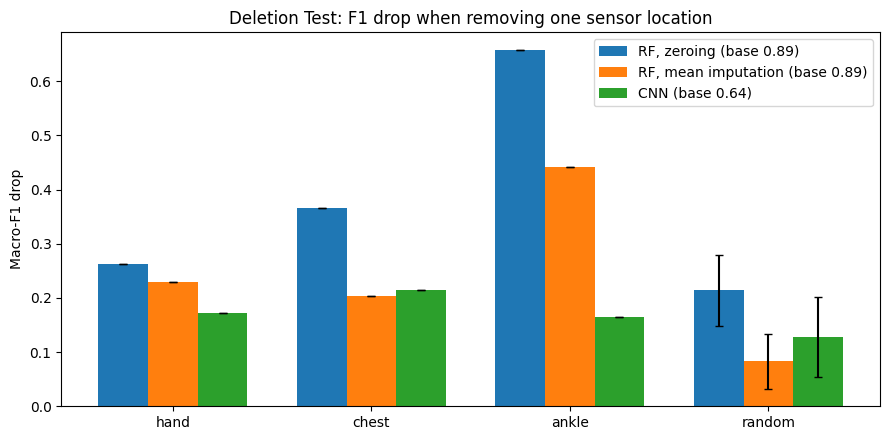

In [10]:
import numpy as np
import matplotlib.pyplot as plt

labels = ['hand', 'chest', 'ankle', 'random']
rf_zero = [0.2623, 0.3655, 0.6574, 0.2141]
rf_mean = [0.2302, 0.2037, 0.4410, 0.0831]
cnn = [0.1724, 0.2152, 0.1648, 0.1277]
rf_zero_err = [0, 0, 0, 0.0650]
rf_mean_err = [0, 0, 0, 0.0506]
cnn_err = [0, 0, 0, 0.0739]

x = np.arange(4)
w = 0.25
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.bar(x - w, rf_zero, w, yerr=rf_zero_err, capsize=3, label='RF, zeroing (base 0.89)')
ax.bar(x, rf_mean, w, yerr=rf_mean_err, capsize=3, label='RF, mean imputation (base 0.89)')
ax.bar(x + w, cnn, w, yerr=cnn_err, capsize=3, label='CNN (base 0.64)')
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_ylabel('Macro-F1 drop')
ax.set_title('Deletion Test: F1 drop when removing one sensor location')
ax.legend()
plt.tight_layout()
plt.savefig('deletion_test.png', dpi=200)
plt.show()